# Projet ML : classification binaire sur Diabetes Health Indicators

Jeu BRFSS 2015 (Kaggle) : prédire si une personne est diabétique ou pré-diabétique (`Diabetes_binary = 1`) à partir de 21 indicateurs de santé et de mode de vie. On applique le même workflow (`ml_workflow.py`) que pour Spambase. Les deux difficultés propres à ce jeu sont le déséquilibre (environ 14 % de positifs) et la taille (253 680 lignes).

Le modèle, les hyperparamètres et le seuil sont choisis par validation croisée sur le train. Pour garder des temps raisonnables, la validation croisée et le réglage se font sur un sous-échantillon stratifié de 30 000 lignes du train ; les modèles finaux sont réentraînés sur le train complet.

In [10]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
import ml_workflow as ml

pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100
SEED = ml.RANDOM_STATE
N_SUB = 30_000  # taille du sous-échantillon pour la CV et le réglage

## 1. Import et description des données  


In [11]:
# Loading
df_diabetes = ml.load_diabetes()

# what it looks like
display(df_diabetes.head())

# Dimension
print("Dimensions :", df_diabetes.shape)

# General description
display(
    ml.describe_dataset(
        df_diabetes,
        "Diabetes_binary"
    )
)

# Target distribution
display(
    df_diabetes["Diabetes_binary"].value_counts()
)

# percentage distribution
display(
    df_diabetes["Diabetes_binary"]
    .value_counts(normalize=True)
    .mul(100)
)


X_diabetes, y_diabetes = ml.split_features_target(
    df_diabetes,
    "Diabetes_binary"
)

print("X :", X_diabetes.shape)
print("y :", y_diabetes.shape)

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


Dimensions : (253680, 22)


n_rows                                                          253680
n_columns                                                           22
n_features                                                          21
n_missing_values                                                     0
n_duplicated_rows                                                24206
target                                                 Diabetes_binary
class_counts                                 {0.0: 218334, 1.0: 35346}
class_proportions    {0.0: 0.8606669820245979, 1.0: 0.1393330179754...
dtype: object

Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

Diabetes_binary
0.0    86.066698
1.0    13.933302
Name: proportion, dtype: float64

X : (253680, 21)
y : (253680,)


## 2. Valeurs manquantes simulées, split et sous-échantillon

On injecte 5 % de valeurs manquantes (MCAR) pour tester l'imputation, puis on fait un split stratifié 80/20. Le sous-échantillon de 30 000 lignes est tiré dans le train uniquement.

In [12]:
# MCAR simulation of 5% missing values
X_diabetes_missing = ml.inject_missing_values(
    X_diabetes,
    frac=0.05,
    seed=SEED
)

# Stratified separation
X_train_diabetes, X_test_diabetes, y_train_diabetes, y_test_diabetes = ml.split_data(
    X_diabetes_missing,
    y_diabetes,
    test_size=0.2,
    seed=SEED
)

print("Train :", X_train_diabetes.shape)
print("Test :", X_test_diabetes.shape)

print("\nDistribution du train :")
display(y_train_diabetes.value_counts(normalize=True))

print("\nDistribution du test :")
display(y_test_diabetes.value_counts(normalize=True))

print("\nValeurs manquantes train :")
print(X_train_diabetes.isna().sum().sum())

print("\nValeurs manquantes test :")
print(X_test_diabetes.isna().sum().sum())

# Subsample for future cross-validation operations
X_sub, y_sub = ml.subsample(
    X_train_diabetes,
    y_train_diabetes,
    n=N_SUB,
    seed=SEED
)

print("\nSous-échantillon :", X_sub.shape)

display(y_sub.value_counts(normalize=True))

Train : (202944, 21)
Test : (50736, 21)

Distribution du train :


Diabetes_binary
0.0    0.860666
1.0    0.139334
Name: proportion, dtype: float64


Distribution du test :


Diabetes_binary
0.0    0.860671
1.0    0.139329
Name: proportion, dtype: float64


Valeurs manquantes train :
213153

Valeurs manquantes test :
53211

Sous-échantillon : (30000, 21)


Diabetes_binary
0.0    0.860667
1.0    0.139333
Name: proportion, dtype: float64

Imputation par la moyenne ou par la médiane : comparaison en validation croisée sur le sous-échantillon, avec une régression logistique pondérée.

In [13]:
imputation_table = pd.concat({
    strategy: ml.cross_validate_models(
        {"lr": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)},
        X_sub, y_sub, cv=5, imputer_strategy=strategy,
    )
    for strategy in ("mean", "median")
}).droplevel(1)
imputation_table.round(3)

,f1_mean,f1_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,fit_time_s
mean,0.438,0.011,0.819,0.009,0.402,0.019,0.069
median,0.436,0.010,0.817,0.010,0.398,0.019,0.260


Moyenne et médiane sont équivalentes : PR-AUC de 0,402 ± 0,019 contre 0,398 ± 0,019. L'écart est bien inférieur à l'écart-type. On garde la médiane par cohérence avec Spambase ; sur ces variables souvent binaires ou entières, elle a aussi l'avantage de produire une valeur possible.

## 3. Gestion du déséquilibre

On commence par un classifieur naïf qui prédit toujours la classe majoritaire : c'est la référence à battre, et elle montre pourquoi l'accuracy seule ne suffit pas ici.

In [14]:
print(y_train_diabetes.value_counts(normalize=True).round(3))

# Classifieur naïf (« toujours non ») : C'est la référence à battre
dummy = Pipeline([("model", DummyClassifier(strategy="prior"))]).fit(X_train_diabetes, y_train_diabetes)
base = ml.evaluate_model(dummy, X_test_diabetes, y_test_diabetes)   # roc_auc = 0.5, pr_auc = prévalence
pd.Series(base, name="Dummy (toujours non)").round(3)



Diabetes_binary
0.0    0.861
1.0    0.139
Name: proportion, dtype: float64


accuracy             0.861
balanced_accuracy    0.500
precision            0.000
recall               0.000
f1                   0.000
mcc                  0.000
roc_auc              0.500
pr_auc               0.139
Name: Dummy (toujours non), dtype: float64

In [15]:
# Effet de class_weight (Cross-validation sur le sous-échantillon du train, pas sur le test)
# On exclut le SVM car il est trop lent sur ces volumes
scoring = ("f1", "average_precision", "balanced_accuracy")
cv_nw = ml.cross_validate_models(ml.get_models(include_svm=False), X_sub, y_sub, cv=3, scoring=scoring)
cv_w  = ml.cross_validate_models(ml.get_models(class_weight="balanced", include_svm=False), X_sub, y_sub, cv=3, scoring=scoring)
pd.concat({"sans pondération": cv_nw, "class_weight=balanced": cv_w}).round(3)

f1_mean  f1_std  average_precision_mean  average_precision_std  balanced_accuracy_mean  balanced_accuracy_std  fit_time_s
sans pondération      lr     0.233   0.010                   0.398                  0.012                   0.564                  0.004       0.104
                      rf     0.201   0.008                   0.363                  0.009                   0.553                  0.003       1.585
                      hgb    0.240   0.018                   0.411                  0.014                   0.567                  0.006       0.444
class_weight=balanced lr     0.438   0.008                   0.398                  0.013                   0.740                  0.008       0.081
                      rf     0.168   0.003                   0.354                  0.005                   0.542                  0.001       1.643
                      hgb    0.436   0.002                   0.415                  0.012                   0.742                  0.000       0.405

La pondération change peu la PR-AUC (HGB : 0,411 sans, 0,415 avec), donc le classement des individus reste le même. En revanche, elle déplace le seuil implicite : le F1 de HGB passe de 0,240 à 0,436 et la balanced accuracy de 0,567 à 0,742. On garde `class_weight="balanced"` pour la suite.

## 4. Comparaison des méthodes (classes pondérées)

Validation croisée à 5 plis sur le sous-échantillon, critère principal PR-AUC (le hasard vaut la prévalence, 0,139).

In [16]:

models = ml.get_models(class_weight="balanced", include_svm=False, random_state=SEED)
cv_table = ml.cross_validate_models(
    models,
    X_sub,
    y_sub,
    cv=5,
    scoring=("f1", "roc_auc", "average_precision"),
)
display(cv_table.round(3).sort_values("average_precision_mean", ascending=False))

,f1_mean,f1_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,fit_time_s
hgb,0.436,0.006,0.820,0.009,0.416,0.023,0.698
lr,0.436,0.010,0.817,0.010,0.398,0.019,0.135
rf,0.176,0.017,0.794,0.007,0.360,0.014,2.024


## 5. Sélection de variables et ACP

Mêmes sélecteurs que pour Spambase, avec k = 5, 10 et 15 sur 21 variables, puis ACP à 95 % de variance, avec une régression logistique pondérée.

In [17]:

selector_model = LogisticRegression(
    class_weight="balanced", max_iter=1000, random_state=SEED
)
selector_table = ml.compare_feature_selectors(
    selector_model,
    X_sub,
    y_sub,
    methods=("anova", "mutual_info", "l1", "rf"),
    k_values=(5, 10, 15),
    cv=5,
    scoring="average_precision",
)
display(selector_table.round(3).sort_values("average_precision_mean", ascending=False))

pca_table = ml.compare_pca(
    selector_model,
    X_sub,
    y_sub,
    pca_components=(None, 0.95),
    cv=5,
    scoring="average_precision",
)
display(pca_table.round(3).sort_values("average_precision_mean", ascending=False))


average_precision_mean  average_precision_std  fit_time_s
method      k                                                            
l1          15                   0.398                  0.018       0.204
            10                   0.397                  0.019       0.189
anova       15                   0.396                  0.018       0.156
mutual_info 15                   0.396                  0.018       1.610
anova       10                   0.394                  0.018       0.111
mutual_info 10                   0.394                  0.018       1.668
rf          15                   0.391                  0.019       2.106
l1          5                    0.389                  0.018       0.200
mutual_info 5                    0.387                  0.019       1.769
anova       5                    0.384                  0.017       0.150
rf          10                   0.377                  0.016       2.038
            5                    0.359                  0.018       1.897

,average_precision_mean,average_precision_std,fit_time_s
none,0.398,0.019,0.110
0.95,0.391,0.019,0.111


Toutes les méthodes sont proches : le meilleur résultat (L1, k = 10 : 0,399 ± 0,019) est au niveau du modèle sans sélection (0,398). Avec k = 5, on perd un peu (0,384 à 0,389, sauf RF à 0,359). L'ACP baisse légèrement la PR-AUC (0,391). Sélectionner des variables permet donc de simplifier sans perte, mais pas de gagner.

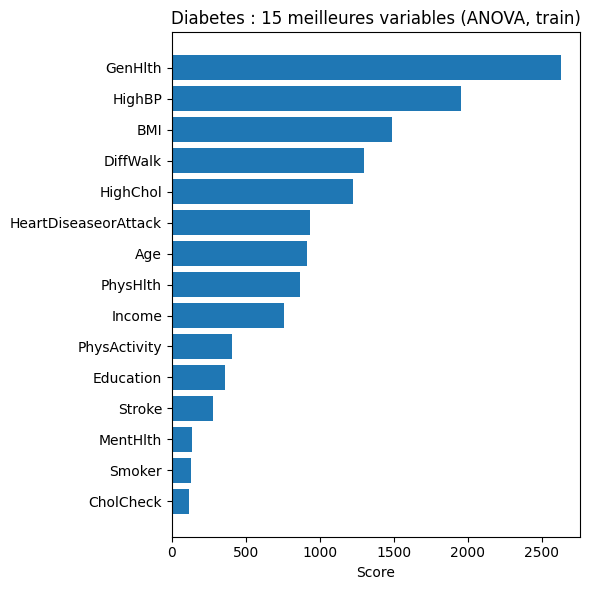

In [18]:
# Scores ANOVA calculés sur le sous-échantillon du train
ml.plot_feature_scores(ml.feature_scores(X_sub, y_sub, "anova"), top=15,
                       title="Diabetes : 15 meilleures variables (ANOVA, train)");

L'état de santé général déclaré (`GenHlth`), l'hypertension, l'IMC, les difficultés à marcher et le cholestérol sont les variables les plus liées au diabète, ce qui est cohérent avec la littérature médicale. Les variables d'accès aux soins (`AnyHealthcare`, `NoDocbcCost`) apportent très peu.

## 6. Réglage de HistGradientBoosting

Grille sur le sous-échantillon (3 plis, critère PR-AUC). `tune_model` réentraîne ensuite la meilleure configuration sur le train complet.

In [19]:
hgb = HistGradientBoostingClassifier(
    class_weight="balanced", random_state=SEED
)
hgb_pipe = ml.build_pipeline(hgb)
hgb_grid = ml.tune_model(
    hgb_pipe,
    {
        "model__learning_rate": [0.03, 0.1],
        "model__max_iter": [100, 200],
        "model__l2_regularization": [0.0, 1.0],
    },
    X_train_diabetes,
    y_train_diabetes,
    scoring="average_precision",
    cv=3,
    n_samples=N_SUB,
)
print("Meilleurs hyperparamètres :", hgb_grid.best_params_)
print("Meilleur score PR-AUC (CV sur sous-échantillon) :", round(hgb_grid.best_score_, 3))

Meilleurs hyperparamètres : {'model__l2_regularization': 1.0, 'model__learning_rate': 0.1, 'model__max_iter': 100}
Meilleur score PR-AUC (CV sur sous-échantillon) : 0.414


## 7. Configuration finale et évaluation sur le test

On vérifie d'abord sur le sous-échantillon si HGB réglé gagne à utiliser une sélection de variables ou l'ACP. Puis on évalue sur le test le modèle retenu, au seuil 0,5 et au seuil qui maximise le F1 sur des scores hors-échantillon du train.

In [20]:
# Modèle final : le meilleur de la section 4 (PR-AUC en CV), réglé en section 6.
# tune_model a déjà réentraîné le meilleur pipeline sur le train complet.
best_name = cv_table["average_precision_mean"].idxmax()
print("Meilleur modèle en CV (section 4) :", best_name)
assert best_name == "hgb", "Le modèle réglé en section 6 est HGB : adapter `final` si le meilleur est un autre modèle."
final = hgb_grid.best_estimator_

Meilleur modèle en CV (section 4) : hgb


In [21]:
# La sélection de variables et l'ACP aident-elles le modèle RETENU (HGB réglé) ? CV sur le sous-échantillon, train uniquement

hgb_tuned = clone(hgb_grid.best_estimator_.named_steps["model"])
cfg = {
    "sans sélection ni ACP": {},
    "ANOVA (k=15)": dict(selector="anova", k=15),
    "information mutuelle (k=15)": dict(selector="mutual_info", k=15),
    "L1 (k=15)": dict(selector="l1", k=15),
    "RF (k=15)": dict(selector="rf", k=15),
    "ACP (95 % de variance)": dict(pca_components=0.95),
}
hgb_cfg_table = pd.DataFrame({
    label: ml.cross_validate_models({"hgb": hgb_tuned}, X_sub, y_sub, cv=5,
                                    scoring=("f1", "average_precision"), **kw).loc["hgb"]
    for label, kw in cfg.items()
}).T
display(hgb_cfg_table.round(3).sort_values("average_precision_mean", ascending=False))

,f1_mean,f1_std,average_precision_mean,average_precision_std,fit_time_s
sans sélection ni ACP,0.435,0.006,0.418,0.022,0.526
ANOVA (k=15),0.431,0.005,0.415,0.025,0.412
information mutuelle (k=15),0.431,0.007,0.415,0.022,2.077
L1 (k=15),0.437,0.006,0.415,0.021,0.507
RF (k=15),0.429,0.006,0.409,0.020,2.358
ACP (95 % de variance),0.431,0.010,0.398,0.019,0.561


In [22]:
# Comparaison diagnostique sur le test des variantes déjà sélectionnées sur le train.
# Cette table ne sert pas à choisir le modèle : le choix doit venir de la CV train.
variants = {
    "HGB pondéré (réglé)": hgb_grid.best_estimator_,
    "Régression logistique pondérée": ml.build_pipeline(
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)
    ),
    "Random Forest pondéré": ml.build_pipeline(
        ml.get_models(class_weight="balanced", include_svm=False, random_state=SEED)["rf"]
    ),
}

variant_rows = {}
variant_fitted = {}
for label, pipe in variants.items():
    fitted_pipe = ml.clone(pipe).fit(X_train_diabetes, y_train_diabetes)
    variant_fitted[label] = fitted_pipe
    variant_rows[label] = ml.evaluate_model(fitted_pipe, X_test_diabetes, y_test_diabetes)

variant_test = pd.DataFrame(variant_rows).T.round(3)
display(variant_test.sort_values("pr_auc", ascending=False))

# Modèle final retenu par la logique train/CV : HGB pondéré réglé.
best_name = cv_table["average_precision_mean"].idxmax()
print("Meilleur modèle en CV (section 4) :", best_name)
assert best_name == "hgb", "Adapter `final` si la meilleure moyenne CV n'est plus HGB."
final = hgb_grid.best_estimator_

# Seuil appris uniquement sur les scores hors-échantillon du train.
oof = ml.oof_scores(final, X_train_diabetes, y_train_diabetes, cv=3)
thr = ml.find_best_threshold(y_train_diabetes, oof, metric="f1")
final.fit(X_train_diabetes, y_train_diabetes)

res = pd.DataFrame({
    "seuil par défaut": ml.evaluate_model(final, X_test_diabetes, y_test_diabetes),
    f"seuil optimisé ({thr:.2f})": ml.evaluate_model(
        final, X_test_diabetes, y_test_diabetes, threshold=thr
    ),
}).round(3)
res

,accuracy,balanced_accuracy,precision,recall,f1,mcc,roc_auc,pr_auc
HGB pondéré (réglé),0.715,0.747,0.301,0.792,0.436,0.355,0.822,0.414
Régression logistique pondérée,0.730,0.740,0.308,0.753,0.437,0.350,0.814,0.385
Random Forest pondéré,0.854,0.556,0.432,0.143,0.215,0.186,0.784,0.337


Meilleur modèle en CV (section 4) : hgb


,seuil par défaut,seuil optimisé (0.65)
accuracy,0.715,0.803
balanced_accuracy,0.747,0.721
precision,0.301,0.373
recall,0.792,0.608
f1,0.436,0.463
mcc,0.355,0.366
roc_auc,0.822,0.822
pr_auc,0.414,0.414


Sur le test, HGB obtient une PR-AUC de 0,414 (environ trois fois la prévalence) et un rappel de 0,792 au seuil 0,5, mais une précision de 0,301 : environ 7 alertes sur 10 sont fausses. Le seuil appris sur le train (0,65) monte la précision à 0,373 et le F1 de 0,436 à 0,463, au prix d'un rappel de 0,608. La régression logistique a un F1 équivalent (0,437) mais une PR-AUC plus faible (0,385) ; le Random Forest a la meilleure accuracy (0,822) mais ne détecte que 42 % des positifs.

In [23]:
# Doublons : lignes du test ayant un jumeau exact (variables d'origine) dans le train
h = pd.util.hash_pandas_object(X_diabetes, index=False)
twin = h.loc[X_test_diabetes.index].isin(set(h.loc[X_train_diabetes.index])).values
print(f"{twin.sum()} lignes de test sur {len(twin)} ({twin.mean():.1%}) ont un jumeau exact dans le train")
print(f"Prévalence des positifs : avec jumeau {y_test_diabetes[twin].mean():.3f} | sans jumeau {y_test_diabetes[~twin].mean():.3f}")

dup_table = pd.DataFrame({
    label: ml.evaluate_model(final, X_test_diabetes[mask], y_test_diabetes[mask])
    for label, mask in [("test complet", np.ones(len(twin), dtype=bool)), ("avec jumeau", twin), ("sans jumeau", ~twin)]
}).round(3).loc[["recall", "precision", "f1", "roc_auc", "pr_auc"]]
display(dup_table)

6836 lignes de test sur 50736 (13.5%) ont un jumeau exact dans le train
Prévalence des positifs : avec jumeau 0.053 | sans jumeau 0.153


,test complet,avec jumeau,sans jumeau
recall,0.792,0.433,0.811
precision,0.301,0.231,0.304
f1,0.436,0.301,0.442
roc_auc,0.822,0.825,0.812
pr_auc,0.414,0.236,0.421


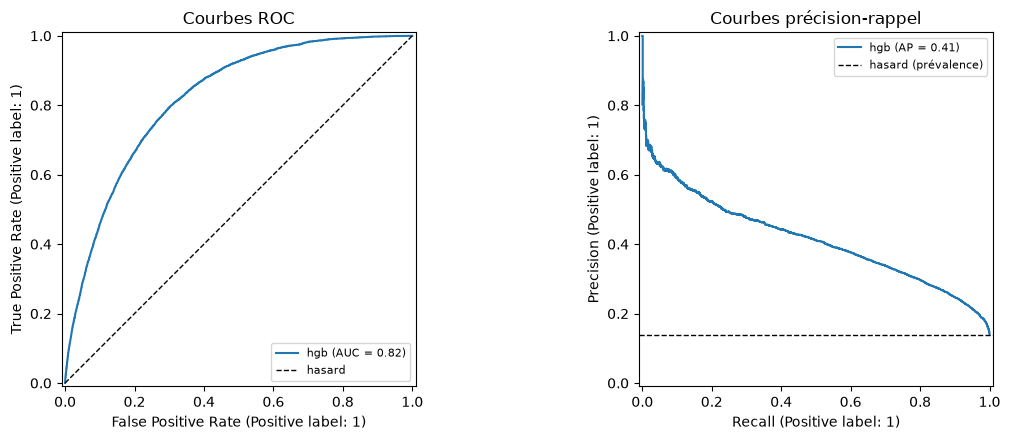

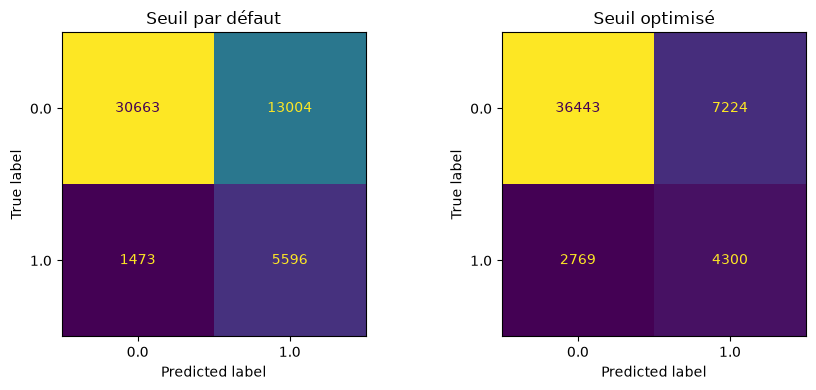

In [26]:
# Courbes ROC / PR et matrices de confusion du modèle final
ml.plot_roc_pr({best_name: final}, X_test_diabetes, y_test_diabetes)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
ml.plot_confusion(final, X_test_diabetes, y_test_diabetes, title="Seuil par défaut", ax=axes[0])
ml.plot_confusion(final, X_test_diabetes, y_test_diabetes, threshold=thr, title="Seuil optimisé", ax=axes[1])
plt.tight_layout()

## 8. Conclusions pour Diabetes Health Indicators  


In [27]:
print("Modèle retenu : HGB pondéré, sans ACP")
print("ROC-AUC test :", round(res.loc["roc_auc", "seuil par défaut"], 3))
print("PR-AUC test :", round(res.loc["pr_auc", "seuil par défaut"], 3))
print("Seuil optimisé :", round(thr, 2))

print("\nVariantes comparées sur le test, sans les utiliser pour changer le choix :")
display(variant_test.sort_values("pr_auc", ascending=False))

Modèle retenu : HGB pondéré, sans ACP
ROC-AUC test : 0.822
PR-AUC test : 0.414
Seuil optimisé : 0.65

Variantes comparées sur le test, sans les utiliser pour changer le choix :


,accuracy,balanced_accuracy,precision,recall,f1,mcc,roc_auc,pr_auc
HGB pondéré (réglé),0.715,0.747,0.301,0.792,0.436,0.355,0.822,0.414
Régression logistique pondérée,0.730,0.740,0.308,0.753,0.437,0.350,0.814,0.385
Random Forest pondéré,0.822,0.655,0.378,0.424,0.399,0.296,0.789,0.335


Dans cette seconde étude, on cherche à identifier les personnes diabétiques ou pré-diabétiques à partir de 21 indicateurs de santé et de mode de vie. La difficulté principale est le déséquilibre car seulement 13,9 % des individus sont positifs.

**Méthode retenue : HistGradientBoosting (`class_weight="balanced"`, `learning_rate=0,1`, `max_iter=100`, `l2_regularization=1,0`), sur les 21 variables, sans ACP.**

**Déséquilibre et choix des métriques.** Le classifieur naïf « toujours non » obtient une accuracy de 0,861 mais un rappel nul et une balanced accuracy de 0,500. L'accuracy peut paraître assez bonne mais dans ce cas, elle est trompeuse. Les modèles sont donc comparés avec la PR-AUC (référence du hasard : la prévalence, 0,139), le F1, le rappel, la balanced accuracy et le MCC.

**Effet de la pondération des classes.** Mesurée par validation croisée sur le sous-échantillon de 30 000 lignes, la pondération ne change presque pas le classement des individus (PR-AUC de HGB : 0,411 → 0,415), mais elle déplace fortement le seuil de décision implicite. En effet, le F1 passe de 0,240 à 0,436 et la balanced accuracy de 0,567 à 0,742 ce qui representent dans changements importants. Elle rend les positifs détectables sans améliorer le pouvoir de classement.

**Choix du modèle.** La comparaison (CV à cinq plis, **sous-échantillon de 30 000 lignes du train**, classes pondérées) donne une PR-AUC de 0,416 ± 0,023 pour HGB, 0,398 ± 0,019 pour la régression logistique et 0,355 ± 0,019 pour le Random Forest. On constate que HGB a la meilleure moyenne, mais son écart avec la régression logistique est modeste au regard de la variabilité entre plis. celle-ci, plus simple et interprétable, reste une alternative défendable.Cependant, on decide de retenir HGB. On constate aussi que le réglage de HGB (grille sur le même sous-échantillon, PR-AUC de 0,414) n'apporte pas de gain mesurable.

**Sélection de variables et ACP.** Avec la régression logistique, L1 (k = 15) atteint 0,398 comme sans sélection, et l'ACP à 95 % 0,391. Ces tests ont ensuite été refaits **directement sur HGB** : sans sélection ni ACP 0,418 ± 0,022 ; ANOVA, information mutuelle et L1 (k = 15) 0,415 ; RF (k = 15) 0,409 ; ACP 0,399. Aucune réduction ne dépasse la configuration complète, et ces écarts restent dans le bruit : toutes les variables sont conservées.

**Évaluation finale.** Sur le test (50 736 individus), HGB obtient une ROC-AUC de 0,822 et une PR-AUC de 0,414, soit environ trois fois le hasard. Au seuil 0,5, le rappel est de 0,792 mais la précision n'est que de 0,301 ce qui signifie que  environ sept alertes sur dix sont de fausses alertes. À titre de contrôle, et sans changer le choix du modèle, la régression logistique a un F1 équivalent (0,437 contre 0,436) mais une PR-AUC plus faible (0,385), et le Random Forest, qui a l'accuracy la plus élevée (0,822), ne détecte que 42 % des positifs.

**Seuil de décision.** Le seuil maximisant le F1 sur les scores hors-échantillon du train vaut 0,65 (le modèle étant pondéré, le seuil optimal dépasse 0,5). Il fait passer la précision de 0,301 à 0,373 et le F1 de 0,436 à 0,463, mais le rappel de 0,792 à 0,608. ROC-AUC et PR-AUC sont inchangées : le seuil déplace seulement le point de fonctionnement. Il s'agit d'un compromis mathématique, pas d'une recommandation clinique : pour un dépistage, où manquer un malade coûte cher, le seuil par défaut est préférable ; le seuil 0,65 limite les examens inutiles.

**Doublons.** Le jeu contient 24 206 lignes dupliquées. Pour mesurer l'effet sur l'évaluation, nous avons identifié les lignes de test ayant un jumeau exact dans le train : 13,5 % (6 836 lignes). Elles ne gonflent pas les scores : leur rappel est plus faible (0,433 contre 0,811) et leur PR-AUC aussi (0,236 contre 0,421), car ce sont surtout des profils sains très courants (5,3 % de positifs contre 15,3 %). Sans ces lignes, la PR-AUC (0,421) est proche de celle du test complet (0,414) : pas de biais optimiste visible. Cette analyse se limite à un seul découpage.

**Limites et perspectives.** Les indicateurs sont auto-déclarés (BRFSS 2015) et le pouvoir de discrimination reste modeste (PR-AUC de 0,41). Les valeurs manquantes sont simulées (MCAR, 5 %). La comparaison et le réglage reposent sur un sous-échantillon de 30 000 lignes et un seul découpage train/test ; une validation répétée ou des comparaisons appariées sur les plis permettraient de confirmer les écarts faibles. Le critère F1 du seuil est arbitraire en l'absence de coûts cliniques précis, et les résultats ne permettent aucune conclusion causale.